Extracted data_exp8.zip successfully.
Loaded 2225 articles.
Matrix shape: (2225, 7597)


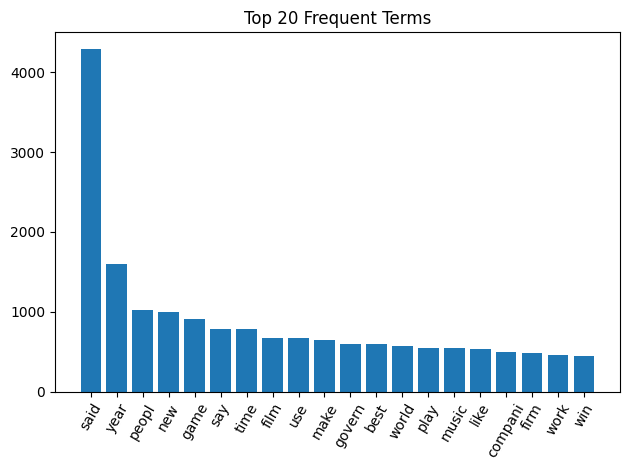

Topic 1: game, said, play, win, year, england, player, time, world, final
Topic 2: said, year, sale, bank, compani, month, price, new, share, club
Topic 3: said, govern, peopl, say, use, law, new, lord, secur, firm
Topic 4: said, peopl, game, music, use, mobil, phone, technolog, servic, year
Topic 5: said, film, best, labour, elect, parti, blair, award, brown, year
                               filename   Topic_1   Topic_2   Topic_3  \
0  data_exp8/Summaries/business/481.txt  0.002488  0.807599  0.002463   
1  data_exp8/Summaries/business/378.txt  0.004404  0.814166  0.172668   
2  data_exp8/Summaries/business/014.txt  0.002265  0.150206  0.096592   
3  data_exp8/Summaries/business/410.txt  0.005177  0.567355  0.005190   
4  data_exp8/Summaries/business/157.txt  0.291023  0.004169  0.629394   
5  data_exp8/Summaries/business/199.txt  0.002565  0.098750  0.893472   
6  data_exp8/Summaries/business/455.txt  0.002454  0.610780  0.281734   
7  data_exp8/Summaries/business/440.txt  0.00301

In [ ]:
import pandas as pd
import numpy as np
import re, glob, zipfile, os
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from nltk.stem import PorterStemmer

# 1. Extract ZIP file
zip_path = "/content/archive.zip"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content")

# 2. Read text files
files = glob.glob("/content/**/Summaries/**/*.txt", recursive=True)

df = pd.DataFrame({
    "filename": files,
    "text": [open(f, encoding="utf-8").read() for f in files]
})

print("Loaded", len(df), "articles.")

# 3. Clean text
stem = PorterStemmer()

def clean(text):
    text = re.sub(r"http\S+|www\S+|https\S+|[^a-zA-Z\s]", " ", text.lower())
    return " ".join(stem.stem(w) for w in text.split()
                    if w not in ENGLISH_STOP_WORDS and len(w) > 2)

df["clean_text"] = df.text.apply(clean)

# 4. Convert text into word count
v = CountVectorizer(max_df=0.9, min_df=2)
X = v.fit_transform(df.clean_text)
words = v.get_feature_names_out()

print("Matrix shape:", X.shape)

# 5. Display top 20 frequent words
freq = np.asarray(X.sum(axis=0)).ravel()
idx = freq.argsort()[-20:][::-1]

plt.bar(words[idx], freq[idx])
plt.xticks(rotation=60)
plt.title("Top 20 Frequent Terms")
plt.tight_layout()
plt.show()

# 6. Apply LDA
lda = LatentDirichletAllocation(
    n_components=5, max_iter=20, random_state=42
).fit(X)

# 7. Display topics
for i, topic in enumerate(lda.components_):
    print(f"Topic {i+1}: {', '.join(words[topic.argsort()[-10:][::-1]])}")

# 8. Display topic distribution
result = pd.DataFrame(
    lda.transform(X),
    columns=[f"Topic_{i+1}" for i in range(5)]
)

result.insert(0, "filename", df.filename)
print(result.head(10))